# Results and figures (aggregates only)

> **Research prototype, not a medical device.**

This notebook reads only the aggregate model-metric tables in `results/`; no per-subject data and no EEG-derived data descriptions are shipped. Every group-size cell is at least 5. Regenerating the tables from raw data requires the confidential dataset (`make reproduce DATA=...`).

In [1]:
import sys, warnings
from pathlib import Path

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
for p in (REPO / "src", REPO / "examples"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
warnings.simplefilter("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)
import json

RES = REPO / "results"

## Headline metrics

Out-of-fold performance on the 90 scorable training subjects (24 PTSD, 66 controls) and false-positive rates on held-out groups. `v3` is the previous reference, `C2G` the shipped model.

In [2]:
m = pd.read_csv(RES / "metrics.csv")
cols = ["model", "role", "auc", "auc_lo", "auc_hi", "sensitivity", "control_fpr", "fpr_soma_elderly", "proxy_points"]
m.loc[m.model.isin(["v3", "C1", "C2", "C3", "C4", "C2G"]), cols]

,model,role,auc,auc_lo,auc_hi,sensitivity,control_fpr,fpr_soma_elderly,proxy_points
0,v3,reference,0.7487,0.6294,0.8428,0.3750,0.1364,0.2165,30.5943
1,C1,candidate_sensitivity,0.8157,0.7462,0.8750,0.3750,0.1515,0.2268,34.4033
2,C2,reference_v4.0,0.8163,0.7500,0.8750,0.2083,0.1061,0.1340,36.2969
3,C3,candidate_sensitivity,0.5189,0.3535,0.6730,0.2083,0.0909,0.0825,19.4869
4,C4,candidate_sensitivity,0.7803,0.6686,0.8718,0.0000,0.0000,0.0000,36.8182
5,C2G,shipped,0.8163,0.7500,0.8750,0.2083,0.1061,0.1340,36.2969


## Pre-registered criteria

Criterion 1: the proxy score improves on v3 with a bootstrap interval above 0. Criterion 2: the flip rate does not exceed v3's by more than the tolerance.

In [3]:
pd.read_csv(RES / "criteria.csv")

,model,proxy_points,v3_proxy_points,delta_proxy,delta_proxy_p2_5,delta_proxy_p97_5,criterion1,flip_rate,v3_flip_rate,flip_limit,criterion2,needs_gates
0,C1,34.4033,30.5943,3.8090,0.0758,8.8468,True,0.1064,0.1062,0.1112,True,True
1,C2,36.2969,30.5943,5.7025,1.7833,10.9050,True,0.0889,0.1062,0.1112,True,True
2,C3,19.4869,30.5943,-11.1075,-15.6866,-2.9742,False,0.0691,0.1062,0.1112,True,False
3,C4,36.8182,30.5943,6.2238,-1.3352,14.1406,False,0.0254,0.1062,0.1112,True,False


## Per-batch outcome of the shipped model

Folder totals are withheld under the data agreement; `positive_rate_folders` counts unscorable recordings (fallback score) as negatives.

In [4]:
bt = pd.read_csv(RES / "C2G_batch_table.csv")
bt[["batch", "n_scorable", "n_positive", "positive_rate_scorable", "positive_rate_folders", "median_score"]]

,batch,n_scorable,n_positive,positive_rate_scorable,positive_rate_folders,median_score
0,PTSD,24,5,0.2083,0.2000,0.2946
1,CTRL_B,46,0,0.0000,0.0000,0.1061
2,CTRL_other,20,7,0.3500,0.3333,0.3200
3,SOMA,57,13,0.2281,0.1757,0.2667
4,CTRL_C,37,4,0.1081,0.1000,0.2310
5,CTRL_elderly,21,0,0.0000,0.0000,0.1418


## ROC curves (out of fold, 95% bootstrap band)

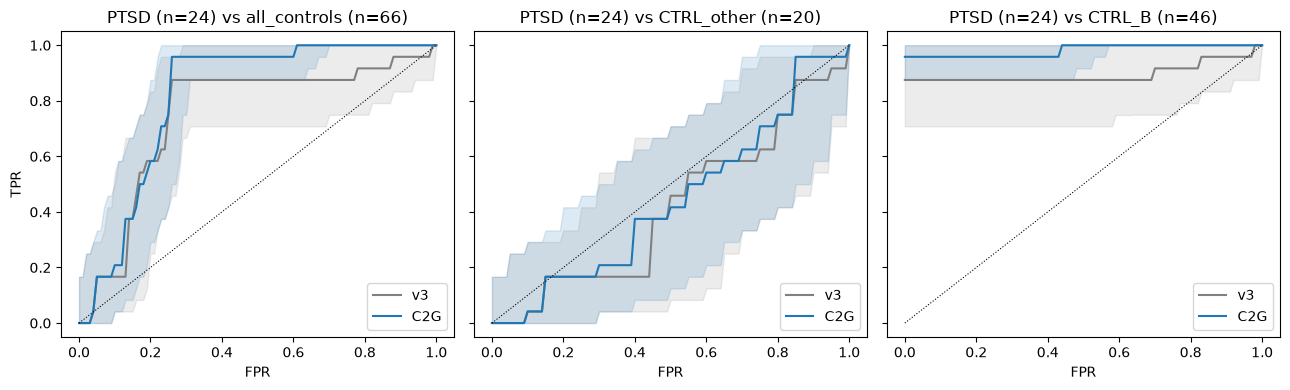

In [5]:
roc = pd.read_csv(RES / "roc_curves.csv")
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, comp in zip(axes, ["all_controls", "CTRL_other", "CTRL_B"]):
    for model, colour in [("v3", "0.5"), ("C2G", "C0")]:
        d = roc[(roc.model == model) & (roc.comparison == comp)]
        ax.plot(d.fpr, d.tpr, color=colour, label=model)
        ax.fill_between(d.fpr, d.tpr_lo, d.tpr_hi, color=colour, alpha=0.15)
    ax.plot([0, 1], [0, 1], "k:", lw=0.8)
    ax.set(title=f"PTSD (n={d.n_ptsd.iloc[0]}) vs {comp} (n={d.n_control.iloc[0]})", xlabel="FPR")
    ax.legend(loc="lower right")
axes[0].set_ylabel("TPR")
plt.tight_layout()

## Ensemble coefficients and weight export check

In [6]:
pd.read_csv(RES / "c2g_coefficients.csv")

,feature,mean,sd,p2_5,median,p97_5,share_positive,sd_across_members,mean_sd_across_bags,n_members,n_bags,p5,p95,member_mean_min,member_mean_max
0,rest_IAF,-0.3081,0.5075,-1.3328,-0.2917,0.7512,0.2433,0.0901,0.4997,90,100,-1.1485,0.4919,-0.5337,-0.0479
1,clr_alpha_O,1.5684,0.9193,0.2176,1.4016,3.7691,0.9866,0.4068,0.7884,90,100,0.3802,3.3283,0.7411,2.7694
2,logit_alpha_IAF,0.5474,0.5016,-0.2939,0.4931,1.6876,0.8904,0.0978,0.4903,90,100,-0.1652,1.4354,0.2476,0.7282
3,clr_beta_O,0.0456,0.7158,-1.2129,-0.0202,1.6047,0.4889,0.2524,0.6513,90,100,-0.9976,1.3282,-0.5164,0.7175


In [7]:
json.loads((RES / "weights_equivalence.json").read_text())

{'check': 'delivered model.pkl (private code, predict CLI) vs public weights (public code, predict CLI)',
 'data': 'every real subject folder of the confidential dataset (training, somatoform, extended controls)',
 'max_abs_diff': 1.6653345369377348e-16,
 'n_decision_changed_at_0_5': 0,
 'source_model_sha256': 'c7e10a708ad9e09f850a13b7578618b15e90f02d832a8b8a63d073236c487ae4',
 'public_weights_sha256': {'c2g_members.npz': '89309e72057da794b899806cf2a819c29cdc58f2e8620f27c6e3d59e38d692fa',
  'model_meta.json': '091b38fc463ff40172763e8b379f75836d105e341c99e3300a21106c8f7f0b3c'},
 'note': 'Nonzero differences, if any, come only from floating-point summation order when the ensemble mean is taken over the permuted member order.'}

Other aggregate tables (audit, external check) are listed in `results/MANIFEST.csv`.

In [8]:
pd.read_csv(RES / "MANIFEST.csv")[["file", "transform", "rows"]]

,file,transform,rows
0,results/metrics.csv,"copied; batch labels neutralised (CTRL_B, CTRL_C)",10.0
1,results/criteria.csv,copied,4.0
2,results/batch_tables.csv,concatenated; batch labels neutralised (CTRL_B...,36.0
3,results/C2G_batch_table.csv,copied (every batch has n >= 20 scorable); bat...,6.0
4,results/flip_summary.csv,dropped run time; batch labels neutralised (CT...,5.0
5,results/sensitivity_analyses.csv,analysis label without subject codes; batch la...,15.0
6,results/negative_controls.csv,source label shortened,4.0
7,results/final_gates_summary.csv,"gate outcomes only (no logs, no paths); batch ...",4.0
8,results/audit/v3_coefficient_spread.csv,copied,4.0
9,results/audit/per_batch_auc_fpr.csv,"copied; batch labels neutralised (CTRL_B, CTRL_C)",8.0
